In [6]:
%matplotlib widget

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))


import matplotlib.pyplot as plt
import numpy as np
from joblib import Parallel, delayed, parallel_config

from serialization.serialize_experiment import load_experiment, read_experiment_metadata


In [7]:
EXPERIMENTS = {
    "2026-11-22T12-15-07-594901Z" : {"name": "Modular Tau", "plot": True},


}

EXPERIMENT_IDs = list(EXPERIMENTS.keys())

In [8]:
experiments = {}

for EXPERIMENT_ID in EXPERIMENT_IDs:

    metadata = read_experiment_metadata(EXPERIMENT_ID)

    ENV_PARAMS = metadata["env_params"]
    HYPER_PARAMS = metadata["hyper_params"]

    seed = metadata["seed"]

    agent, gym_env, _ = load_experiment(EXPERIMENT_ID)

    env = gym_env.qm_env

    experiments[EXPERIMENT_ID] = {
        "agent": agent,
        "gym_env": gym_env, 
        "env": env
    }

In [9]:
def replay(agent, gym_env, env):

    _, actions, _, _ = agent.get_actions(
        gym_env, 
        seed = seed, 
        deterministic=False
    )

    if actions[0] < 0:
        actions = -actions

    return env.replay(actions)

experiment_histories = {}

for i, EXPERIMENT_ID in enumerate(experiments):

    histories = []

    agent = experiments[EXPERIMENT_ID]["agent"]
    gym_env = experiments[EXPERIMENT_ID]["gym_env"]
    env = experiments[EXPERIMENT_ID]["env"]

    with parallel_config(
        backend="loky",
        n_jobs=14,
        inner_max_num_threads=1
    ):
        histories = Parallel()(
            delayed(replay)(agent, gym_env, env)
            for _ in range(50)
        )

    experiment_histories[EXPERIMENT_ID] = histories

    print(
        "[" + str(i+1) + "/" + str(len(EXPERIMENTS)) + "] " 
        + EXPERIMENTS[EXPERIMENT_ID]["name"] 
        + " (" + EXPERIMENT_ID + ")" 
        + " complete!"
    )

[1/1] Modular Tau (2026-11-22T12-15-07-594901Z) complete!



Modular Tau
  Rollouts: 50
  Mean termination time: 5.1720
  Std termination time:  0.4008
  Early stops: 41/50
  Mean early stopping time: 5.0780


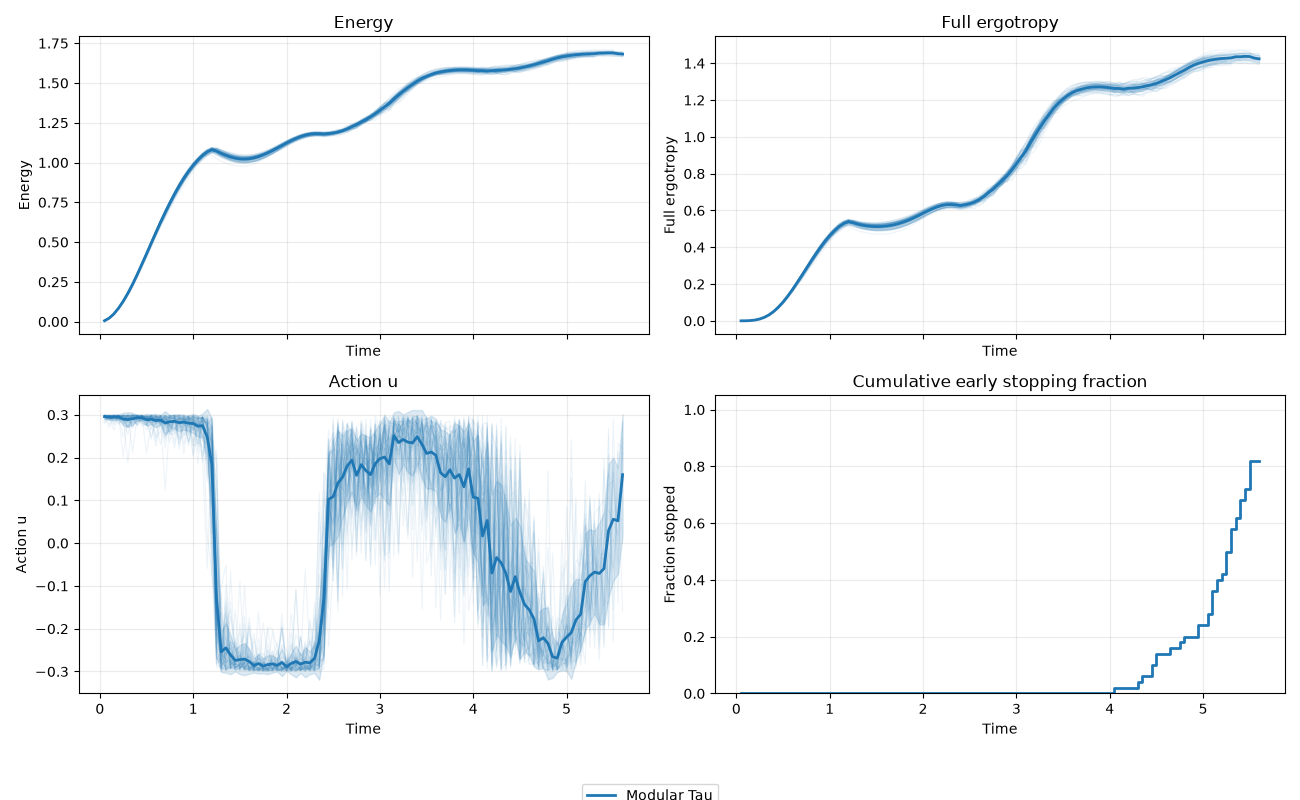

In [ ]:
def plot_sac_results(experiment_histories, experiments):

    quantities = {
        "energy": "Energy",
        "ergotropy_full": "Full ergotropy",
        "action": "Action u",
    }

    fig, axes = plt.subplots(
        2, 2, figsize=(13, 8), sharex=True
    )
    axes = axes.ravel()

    colors = plt.cm.tab10(
        np.linspace(0, 1, len(experiment_histories))
    )

    for (eid, histories), color in zip(
        experiment_histories.items(), colors
    ):
        name = EXPERIMENTS[eid]["name"]
        histories = [h for h in histories if h]

        if not histories:
            continue

        end_times = np.array([
            h[-1]["time"] for h in histories
        ], dtype=float)

        tau = experiments[eid]["env"].tau
        stopped = end_times < tau - 1e-10

        print(f"\n{name}")
        print(f"  Rollouts: {len(histories)}")
        print(f"  Mean termination time: {end_times.mean():.4f}")
        print(f"  Std termination time:  {end_times.std():.4f}")
        print(f"  Early stops: {stopped.sum()}/{len(histories)}")

        if stopped.any():
            print(
                f"  Mean early stopping time: "
                f"{end_times[stopped].mean():.4f}"
            )

        times = np.unique(np.concatenate([
            np.array([entry["time"] for entry in h])
            for h in histories
        ]))

        for ax, (key, title) in zip(
            axes[:3], quantities.items()
        ):
            aligned = []

            for h in histories:
                t = np.array(
                    [entry["time"] for entry in h],
                    dtype=float
                )
                y = np.array(
                    [entry.get(key, np.nan) for entry in h],
                    dtype=float
                )

                ax.plot(t, y, color=color, alpha=0.08, lw=0.8)

                valid = np.isfinite(t) & np.isfinite(y)
                row = np.full(len(times), np.nan)

                if valid.sum() >= 2:
                    row = np.interp(
                        times, t[valid], y[valid],
                        left=np.nan, right=np.nan
                    )
                elif valid.sum() == 1:
                    row[np.isclose(times, t[valid][0])] = y[valid][0]

                aligned.append(row)

            aligned = np.vstack(aligned)

            with np.errstate(invalid="ignore"):
                count = np.sum(np.isfinite(aligned), axis=0)
                total = np.nansum(aligned, axis=0)
                mean = np.divide(
                    total, count,
                    out=np.full(len(times), np.nan),
                    where=count > 0
                )
                std = np.sqrt(np.divide(
                    np.nansum((aligned - mean) ** 2, axis=0),
                    count,
                    out=np.full(len(times), np.nan),
                    where=count > 0
                ))

            ax.plot(times, mean, color=color, lw=2, label=name)
            ax.fill_between(
                times, mean - std, mean + std,
                color=color, alpha=0.15
            )
            ax.set_title(title)
            ax.set_ylabel(title)
            ax.grid(alpha=0.25)

        stop_times = end_times[stopped]
        stop_fraction = np.array([
            np.count_nonzero(stop_times <= t) / len(histories)
            for t in times
        ])

        axes[3].step(
            times, stop_fraction,
            where="post", color=color, lw=2, label=name
        )

    axes[3].set_title("Cumulative early stopping fraction")
    axes[3].set_ylabel("Fraction stopped")
    axes[3].set_ylim(0, 1.05)
    axes[3].grid(alpha=0.25)

    for ax in axes:
        ax.set_xlabel("Time")

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels, loc="lower center",
        bbox_to_anchor=(0.5, -0.02),
        ncol=min(4, len(labels))
    )

    fig.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()

    return fig


fig = plot_sac_results(experiment_histories, experiments)



Modular Tau
  Rollouts: 50
  Mean termination time: 5.1720
  Std termination time:  0.4008
  Early stops: 41/50
  Mean early stopping time: 5.0780


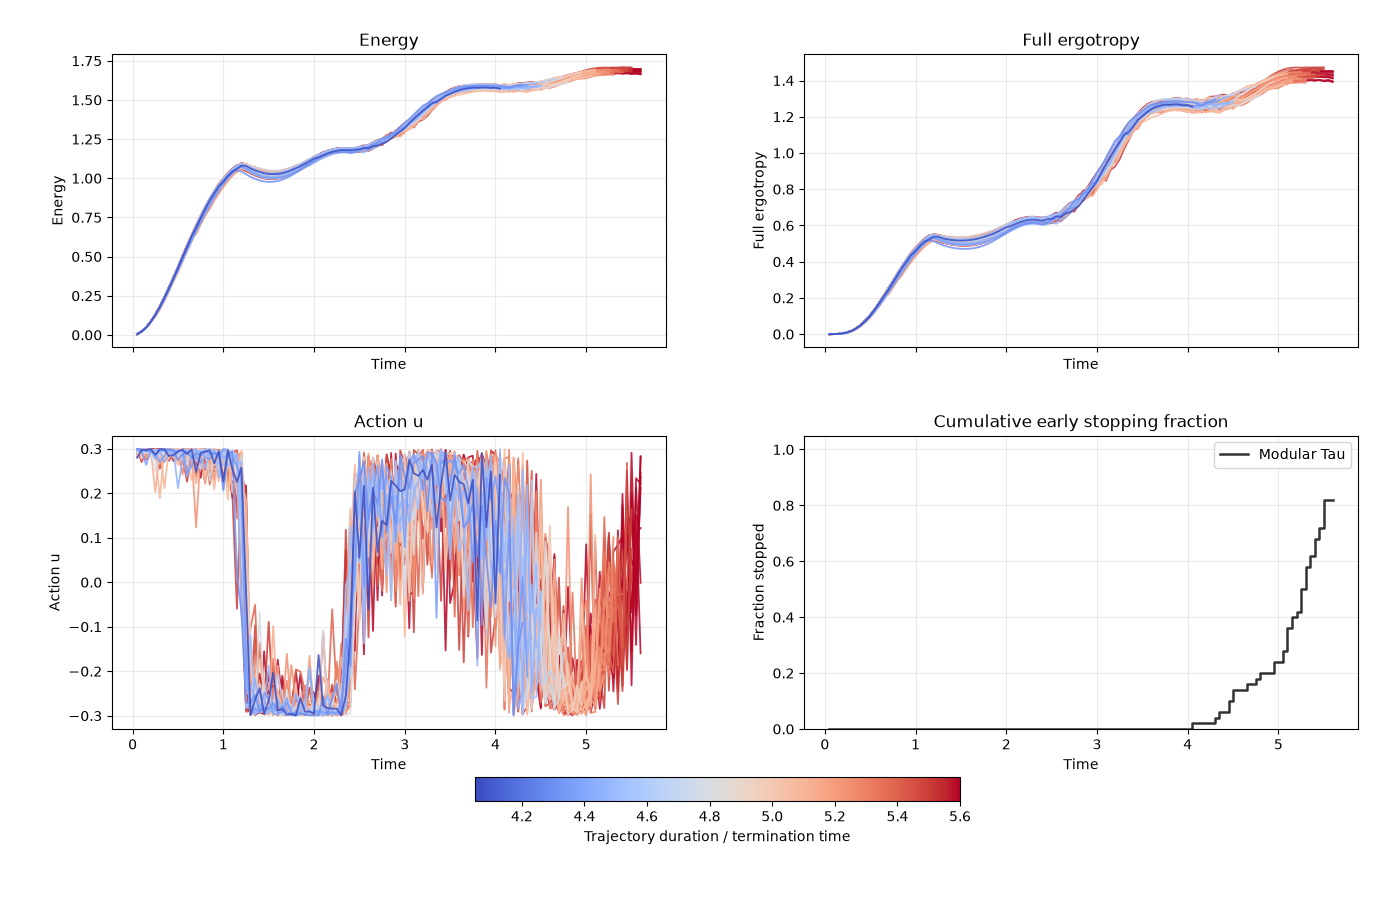

In [ ]:


from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize


def plot_sac_results(experiment_histories, experiments, EXPERIMENTS):

    quantities = {
        "energy": "Energy",
        "ergotropy_full": "Full ergotropy",
        "action": "Action u"
    }

    fig, axes = plt.subplots(
        2, 2, figsize=(14, 9), sharex=True
    )
    axes = axes.ravel()

    all_end_times = np.array([
        h[-1]["time"]
        for histories in experiment_histories.values()
        for h in histories
        if h
    ], dtype=float)

    if len(all_end_times) == 0:
        raise ValueError("No non-empty histories found.")

    min_duration = all_end_times.min()
    max_duration = all_end_times.max()

    cmap = plt.get_cmap("coolwarm")
    norm = Normalize(
        vmin=min_duration,
        vmax=max_duration if max_duration > min_duration
        else min_duration + 1e-10
    )

    for eid, histories in experiment_histories.items():

        name = EXPERIMENTS[eid]["name"]
        histories = [h for h in histories if h]

        if not histories:
            continue

        end_times = np.array([
            h[-1]["time"] for h in histories
        ], dtype=float)

        tau = experiments[eid]["env"].tau
        stopped = end_times < tau - 1e-10

        print(f"\n{name}")
        print(f"  Rollouts: {len(histories)}")
        print(f"  Mean termination time: {end_times.mean():.4f}")
        print(f"  Std termination time:  {end_times.std():.4f}")
        print(f"  Early stops: {stopped.sum()}/{len(histories)}")

        if stopped.any():
            print(
                f"  Mean early stopping time: "
                f"{end_times[stopped].mean():.4f}"
            )

        sorted_histories = sorted(
            histories,
            key=lambda h: h[-1]["time"],
            reverse=True
        )

        for h in sorted_histories:

            t = np.array([
                entry["time"] for entry in h
            ], dtype=float)

            duration = t[-1]
            color = cmap(norm(duration))

            for ax, (key, title) in zip(
                axes[:3], quantities.items()
            ):
                y = np.array([
                    entry.get(key, np.nan) for entry in h
                ], dtype=float)

                ax.plot(
                    t, y,
                    color=color,
                    alpha=0.85,
                    lw=1.3,
                    zorder=1000 - duration
                )

                ax.set_title(title)
                ax.set_ylabel(title)
                ax.grid(alpha=0.25)

        times = np.unique(np.concatenate([
            np.array([entry["time"] for entry in h])
            for h in histories
        ]))

        stop_times = end_times[stopped]

        stop_fraction = np.array([
            np.count_nonzero(stop_times <= t) / len(histories)
            for t in times
        ])

        axes[3].step(
            times,
            stop_fraction,
            where="post",
            color="black",
            alpha=0.8,
            lw=1.8,
            label=name
        )

    axes[3].set_title("Stopping fraction")
    axes[3].set_ylabel("Fraction stopped")
    axes[3].set_ylim(0, 1.05)
    axes[3].grid(alpha=0.25)

    for ax in axes:
        ax.set_xlabel("Time")

    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    fig.colorbar(
        sm,
        ax=axes.tolist(),
        orientation="horizontal",
        fraction=0.035,
        pad=0.10,
        label="termination time"
    )

    axes[3].legend()

    fig.subplots_adjust(
        left=0.08,
        right=0.97,
        top=0.94,
        bottom=0.19,
        hspace=0.30,
        wspace=0.25
    )

    plt.show()

    return fig


fig = plot_sac_results(
    experiment_histories,
    experiments,
    EXPERIMENTS
)
